# 03. Khám phá Dữ liệu Sạch (EDA) & Phân tích Tiền tắc nghẽn

> Khám phá dữ liệu giao thông sạch (`PEMS08` là tập nghiên cứu chính, `PEMS04` là tập đối chiếu) theo trình tự từ quan sát tổng thể chuỗi thời gian dài hạn đến cấu trúc mạng lưới và động lực trước thời điểm tắc nghẽn.

### Tóm tắt
* **Bối cảnh:** Kế thừa hai bộ dữ liệu đã làm sạch hoàn toàn ở [02. Làm sạch Dữ liệu & Nội suy Chuỗi Thời gian (`02_Data_Cleaning_and_Interpolation.ipynb`)](./02_Data_Cleaning_and_Interpolation.ipynb).
* **Các câu hỏi dẫn dắt của bước này:**
  1. Hệ thống giao thông vận hành theo chu kỳ ngày – tuần nào?
  2. Ranh giới vật lý nào phân tách trạng thái thông thoáng với tắc nghẽn?
  3. Tắc nghẽn phân bố đều hay tập trung ở một nhóm nút thắt cổ chai?
  4. Chỉ số cấu trúc mạng tĩnh giải thích được bao nhiêu, và có dấu hiệu sớm nào xuất hiện trước lúc khởi phát tắc nghẽn hay không?
* **Kết quả đầu ra:** Bảng chỉ số mạng & điểm nghẽn (`outputs/PEMS08_bottlenecks.csv`, `outputs/PEMS04_bottlenecks.csv`), tệp đồ thị Gephi (`.gexf`) và hệ thống biểu đồ EDA 300 DPI.

---
## 1. Thiết lập môi trường & Nạp dữ liệu sạch

Ta nạp chuỗi thời gian sạch `(T, N, 3)` và sơ đồ cạnh có hướng `(from, to, cost)` của `PEMS08` và `PEMS04` để sẵn sàng cho cả phân tích chuỗi thời gian lẫn giải phẫu cấu trúc đồ thị.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, ttest_rel

ROOT = Path("..").resolve()
DATA_DIR, CLEAN_DIR, OUT_DIR = ROOT / "datasets" / "data", ROOT / "outputs" / "cleaned", ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300})
SEED = 42
np.random.seed(SEED)

ds = {}
for name in ["PEMS08", "PEMS04"]:
    arr = np.load(CLEAN_DIR / f"{name}_clean.npz")["data"].astype(np.float32)
    edges = pd.read_csv(DATA_DIR / name / f"{name}.csv")
    edges.columns = edges.columns.str.strip().str.lower()
    G = nx.DiGraph()
    G.add_nodes_from(range(arr.shape[1]))
    G.add_weighted_edges_from([(int(u), int(v), max(float(w), 1.0)) for u, v, w in edges.itertuples(index=False)], weight="cost")
    ds[name] = {"data": arr, "edges": edges, "G": G}
    print(f"{name}: tensor={arr.shape}, nodes={G.number_of_nodes()}, edges={G.number_of_edges()}")

PEMS08: tensor=(17856, 170, 3), nodes=170, edges=277
PEMS04: tensor=(16992, 307, 3), nodes=307, edges=340


---
## 2. Toàn cảnh vận hành: Chuỗi thời gian 1 tháng & Nhịp điệu hệ thống

### 2.1. Bức tranh vĩ mô 30 ngày liên tục của cả 3 biến (`PEMS08`)
Bước đầu tiên khi tiếp cận một bộ dữ liệu chuỗi thời gian sạch là quan sát **bức tranh tổng thể qua thời gian dài** trước khi phóng to vào các hiện tượng cục bộ. Ta vẽ diễn biến **30 ngày đầu tiên** (`8.640` bước đo) của cả ba biến `Lưu lượng`, `Độ chiếm dụng` và `Vận tốc` trên toàn bộ `170` trạm của `PEMS08`.

Để tóm tắt 170 trạm tại mỗi thời điểm mà không bị méo bởi vài điểm cực trị, biểu đồ sử dụng các thước đo **phân vị** (xếp 170 trạm theo thứ tự từ nhỏ đến lớn):
* **Trung vị (phân vị 50%):** Giá trị nằm đúng chính giữa mạng lưới (50% số trạm cao hơn và 50% số trạm thấp hơn).
* **Khoảng phân vị 25%–75% (dải màu mờ):** Vùng chứa 50% số trạm nằm ở khoảng giữa, phản ánh mức độ phân tán phổ biến.
* **Phân vị 5% (đường đỏ ở biểu đồ vận tốc):** Mức vận tốc của nhóm 5% trạm chậm nhất (~8–9 trạm chậm nhất trong 170 trạm; 95% trạm còn lại chạy nhanh hơn mức này).

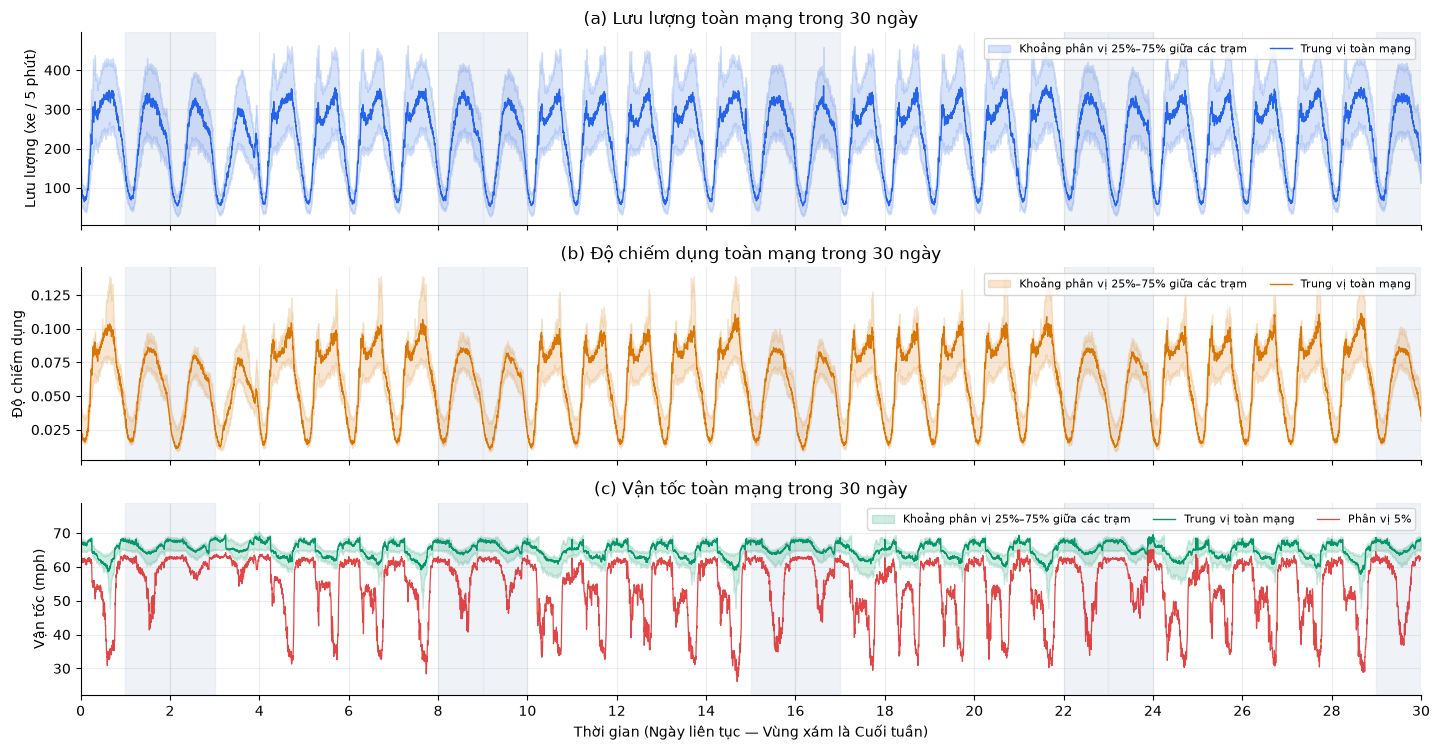

In [2]:
d8 = ds["PEMS08"]["data"]
days_show = 30
T_30 = days_show * 288
t_days = np.arange(T_30) / 288.0
sub30 = d8[:T_30]  # (8640, 170, 3)

fig, axes = plt.subplots(3, 1, figsize=(14.5, 7.6), sharex=True)
meta = [(0, "Lưu lượng (xe / 5 phút)", "#2563eb", "(a) Lưu lượng toàn mạng trong 30 ngày"),
        (1, "Độ chiếm dụng", "#d97706", "(b) Độ chiếm dụng toàn mạng trong 30 ngày"),
        (2, "Vận tốc (mph)", "#059669", "(c) Vận tốc toàn mạng trong 30 ngày")]

# Đánh dấu các ngày cuối tuần (day%7 == 1, 2 là Thứ Bảy, Chủ Nhật)
for day_i in range(days_show):
    if day_i % 7 in [1, 2]:
        for ax in axes:
            ax.axvspan(day_i, day_i + 1, color="#e2e8f0", alpha=0.55, zorder=0)

for f_idx, ylabel, col, title in meta:
    ax = axes[f_idx]
    med = np.median(sub30[:, :, f_idx], axis=1)
    q25, q75 = np.percentile(sub30[:, :, f_idx], [25, 75], axis=1)
    ax.fill_between(t_days, q25, q75, color=col, alpha=0.18, label="Khoảng phân vị 25%–75% giữa các trạm")
    ax.plot(t_days, med, color=col, lw=1.0, label="Trung vị toàn mạng")
    if f_idx == 2:
        q05 = np.percentile(sub30[:, :, 2], 5, axis=1)
        ax.plot(t_days, q05, color="#dc2626", lw=0.9, alpha=0.85, label="Phân vị 5%")
        ax.set_ylim(22, 79)
    ax.set(ylabel=ylabel, title=title)
    ax.legend(loc="upper right", frameon=True, fontsize=8, ncol=3)
    ax.grid(alpha=0.22)

axes[-1].set(xlim=(0, days_show), xticks=range(0, days_show + 1, 2), xlabel="Thời gian (Ngày liên tục — Vùng xám là Cuối tuần)")
plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_one_month_timeseries.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Quan sát vĩ mô 30 ngày):**
>
> * **Tính chu kỳ ổn định:** Bức tranh dài hạn 30 ngày cho thấy mỗi ngày đều lặp lại chu kỳ lên – xuống giữa ban đêm và ban ngày, và cứ sau 5 ngày làm việc lại xuất hiện một nhịp cuối tuần dịu hơn (vùng nền xám đánh dấu Thứ Bảy – Chủ Nhật theo lịch `PEMS08` bắt đầu từ Thứ Sáu `01/07/2016`, có `Lưu lượng` và `Độ chiếm dụng` thấp hơn hẳn, `Vận tốc` phẳng và thông thoáng).
>
> * **Phân hóa cục bộ theo trạm:** Ở biểu đồ `(c)`, dù **trung vị toàn mạng** luôn duy trì ổn định quanh `60–67 mph`, đường **phân vị 5% (màu đỏ)** lại liên tục xuất hiện những nhịp lao dốc mạnh xuống vùng `25–40 mph` đúng vào các thời điểm `Độ chiếm dụng` ở `(b)` tăng cao. Điều này gợi ý rằng hiện tượng suy giảm vận tốc nghiêm trọng thực sự xảy ra theo chu kỳ ngày, nhưng chỉ tập trung ở một tỷ lệ nhỏ các trạm chứ không phủ kín toàn mạng.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Nhịp suy giảm vận tốc này rơi chính xác vào khung giờ nào trong ngày, thứ nào trong tuần, và trong ba biến đo lường, biến nào đi cùng chặt chẽ nhất với sự tụt giảm vận tốc?

### 2.2. Tổng hợp nhịp điệu theo Thứ – Giờ và tương quan giữa ba biến

Từ những gợi ý ở chuỗi thời gian 30 ngày, ta tổng hợp lại thành **bức tranh tóm tắt theo chu kỳ tuần/ngày** và kiểm tra ma trận tương quan giữa ba biến để trả lời hai câu hỏi nối tiếp:
1. *Giờ nào trong ngày và thứ nào trong tuần dễ xảy ra suy giảm tốc độ nhất?*
2. *Trong ba biến, biến nào gắn liền chặt nhất với sự sụt giảm vận tốc?*

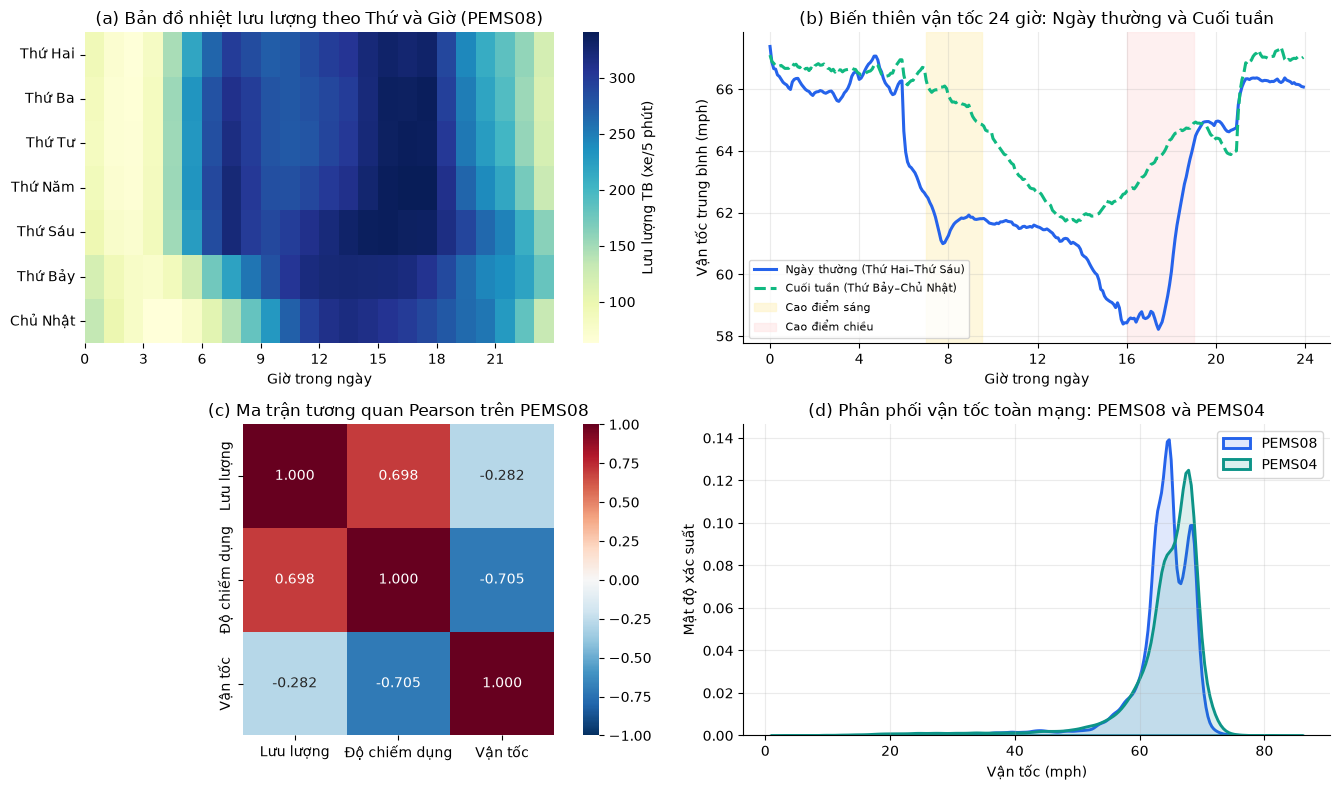

In [3]:
n_days8 = d8.shape[0] // 288
daily8 = d8[: n_days8 * 288].reshape(n_days8, 288, d8.shape[1], 3)
dow_order = [3, 4, 5, 6, 0, 1, 2]
dow_names = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]
heat_flow = np.array([daily8[k::7, :, :, 0].mean(axis=(0, 2)).reshape(24, 12).mean(axis=1) for k in dow_order])

wkday_spd = daily8[np.isin(np.arange(n_days8) % 7, [3, 4, 5, 6, 0]), :, :, 2].mean(axis=(0, 2))
wkend_spd = daily8[np.isin(np.arange(n_days8) % 7, [1, 2]), :, :, 2].mean(axis=(0, 2))
hours = np.arange(288) / 12.0
corr_df = pd.DataFrame(d8.reshape(-1, 3)[::10], columns=["Lưu lượng", "Độ chiếm dụng", "Vận tốc"]).corr()

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.0))
sns.heatmap(heat_flow, ax=axes[0, 0], cmap="YlGnBu", yticklabels=dow_names, cbar_kws={"label": "Lưu lượng TB (xe/5 phút)"})
axes[0, 0].set(xlabel="Giờ trong ngày", title="(a) Bản đồ nhiệt lưu lượng theo Thứ và Giờ (PEMS08)")
axes[0, 0].set_xticks(range(0, 24, 3)); axes[0, 0].set_xticklabels(range(0, 24, 3), rotation=0)

axes[0, 1].plot(hours, wkday_spd, color="#2563eb", lw=2.2, label="Ngày thường (Thứ Hai–Thứ Sáu)")
axes[0, 1].plot(hours, wkend_spd, color="#10b981", lw=2.2, ls="--", label="Cuối tuần (Thứ Bảy–Chủ Nhật)")
axes[0, 1].axvspan(7, 9.5, color="#fef3c7", alpha=0.6, label="Cao điểm sáng")
axes[0, 1].axvspan(16, 19, color="#fee2e2", alpha=0.5, label="Cao điểm chiều")
axes[0, 1].set(xticks=range(0, 25, 4), xlabel="Giờ trong ngày", ylabel="Vận tốc trung bình (mph)",
               title="(b) Biến thiên vận tốc 24 giờ: Ngày thường và Cuối tuần")
axes[0, 1].legend(frameon=True, fontsize=8.2); axes[0, 1].grid(alpha=0.25)

sns.heatmap(corr_df, ax=axes[1, 0], annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
axes[1, 0].set_title("(c) Ma trận tương quan Pearson trên PEMS08")

for nm, c in [("PEMS08", "#2563eb"), ("PEMS04", "#0d9488")]:
    sns.kdeplot(ds[nm]["data"][:, :, 2].ravel()[::30], ax=axes[1, 1], color=c, lw=2.1, fill=True, alpha=0.14, label=nm)
axes[1, 1].set(xlabel="Vận tốc (mph)", ylabel="Mật độ xác suất", title="(d) Phân phối vận tốc toàn mạng: PEMS08 và PEMS04")
axes[1, 1].legend(frameon=True); axes[1, 1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_clean_data_overview.png", bbox_inches="tight")
plt.show()

> **Nhận xét:**
>
> 1. **Hai khung giờ cao điểm ngày thường:** Biểu đồ `(a)` và `(b)` xác nhận cấu trúc hai đỉnh đặc trưng vào các ngày **Thứ Hai–Thứ Sáu**: cao điểm sáng (`07:00–09:30`) và cao điểm chiều (`16:00–19:00`), nơi vận tốc trung bình toàn mạng giảm sâu nhất (xuống ~`58–61 mph`). Trong khi đó, cuối tuần không có đỉnh sáng và vận tốc buổi sáng cao hơn rõ rệt.
>
> 2. **Tương quan giữa ba biến:** Ma trận `(c)` chỉ ra mối liên hệ mô tả trên toàn chuỗi thời gian: **`Độ chiếm dụng`** tương quan nghịch với `Vận tốc` (**`r = -0.705`**), mạnh hơn gấp đôi so với mối liên hệ giữa `Lưu lượng` và `Vận tốc` (`r = -0.282`). Dù hệ số này còn chịu ảnh hưởng một phần bởi tự tương quan và nhịp điệu ngày–đêm chung, nó định hướng rõ câu hỏi tiếp theo:
>
> *Khi độ chiếm dụng tăng đến mức nào thì dòng xe bị gãy pha và rơi vào tắc nghẽn?*

---
## 3. Sơ đồ cơ bản giao thông & Chốt tiêu chí tắc nghẽn từ cả 3 biến

### 3.1. Chuyển pha đồng thời của 3 biến (`Flow – Occupancy – Speed`) & Chốt định nghĩa tắc nghẽn

Để trả lời câu hỏi vừa đặt ra ở Mục 2.2, ta khảo sát **đồng thời cả 3 biến (`Lưu lượng`, `Độ chiếm dụng`, `Vận tốc`)** trên sơ đồ cơ bản giao thông của `PEMS08`. Mục tiêu là phân tích vai trò vật lý của từng biến và **chốt một tiêu chí nhận diện điểm tắc nghẽn thực sự** trước khi áp tiêu chí đó để kiểm chứng sự khác biệt giữa ban ngày và ban đêm ở Mục 3.2.

Khoảng Độ chiếm dụng  Tỷ lệ quan sát (%)  Lưu lượng TB  Vận tốc TB (mph)  Tỷ lệ dưới 40 mph (%)
        [0.00, 0.05)               39.47         105.0              66.6                    0.1
        [0.05, 0.10)               47.23         289.1              64.1                    0.1
        [0.10, 0.15)                9.50         386.1              59.3                    1.6
        [0.15, 0.20)                1.86         433.4              50.1                   19.4
        [0.20, 0.30)                1.48         427.5              35.7                   70.7
        [0.30, 1.00)                0.46         375.2              24.9                   94.8

Đối chiếu 3 biến cho nhóm Speed < 40 mph:
                             Nhóm trạng thái  Số điểm  Tỷ lệ (%)  Flow P5/P25/TV  Occ TV  Speed TV
             Tắc thực (Speed<40 & Occ>=0.15)    55848       1.84 133 / 300 / 402   0.256      31.6
     Chạy chậm vắng xe (Speed<40 & Occ<0.15)     6765       0.22   30 / 77 / 203   0.11

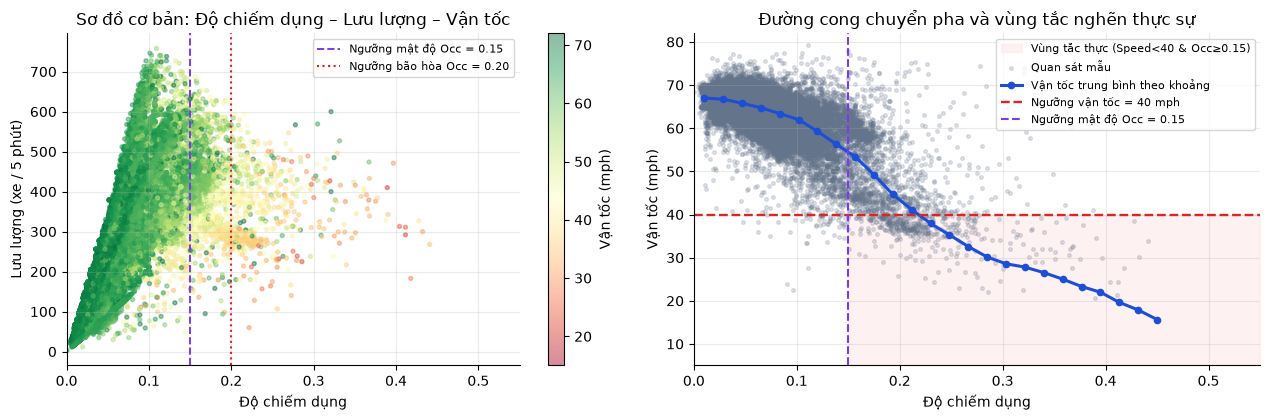

In [4]:
SPEED_TH, OCC_TH = 40.0, 0.15
flat8 = d8.reshape(-1, 3)
flw8, occ8, spd8 = flat8[:, 0], flat8[:, 1], flat8[:, 2]
bins = [(0.0, 0.05), (0.05, 0.10), (0.10, 0.15), (0.15, 0.20), (0.20, 0.30), (0.30, 1.01)]

rows = []
for lo, hi in bins:
    m = (occ8 >= lo) & (occ8 < hi)
    rows.append({
        "Khoảng Độ chiếm dụng": f"[{lo:.2f}, {min(hi, 1.0):.2f})",
        "Tỷ lệ quan sát (%)": round(100.0 * m.mean(), 2),
        "Lưu lượng TB": round(float(flw8[m].mean()), 1),
        "Vận tốc TB (mph)": round(float(spd8[m].mean()), 1),
        "Tỷ lệ dưới 40 mph (%)": round(100.0 * (spd8[m] < SPEED_TH).mean(), 1),
    })
print(pd.DataFrame(rows).to_string(index=False))

grp_rows = []
for lbl, m in [
    ("Tắc thực (Speed<40 & Occ>=0.15)", (spd8 < SPEED_TH) & (occ8 >= OCC_TH)),
    ("Chạy chậm vắng xe (Speed<40 & Occ<0.15)", (spd8 < SPEED_TH) & (occ8 < OCC_TH)),
    ("Tắc cứng quá tải nặng (Speed<40 & Occ>=0.30)", (spd8 < SPEED_TH) & (occ8 >= 0.30)),
]:
    p5, p25, p50 = np.percentile(flw8[m], [5, 25, 50])
    grp_rows.append({
        "Nhóm trạng thái": lbl, "Số điểm": int(m.sum()), "Tỷ lệ (%)": round(100.0 * m.mean(), 2),
        "Flow P5/P25/TV": f"{p5:.0f} / {p25:.0f} / {p50:.0f}",
        "Occ TV": round(float(np.median(occ8[m])), 3), "Speed TV": round(float(np.median(spd8[m])), 1),
    })
print("\nĐối chiếu 3 biến cho nhóm Speed < 40 mph:")
print(pd.DataFrame(grp_rows).to_string(index=False))

sub = flat8[::60]
occ_grid = np.linspace(0.01, 0.45, 25)
mean_spd_curve = [spd8[(occ8 >= o - 0.015) & (occ8 < o + 0.015)].mean() for o in occ_grid]

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.3))
sc = axes[0].scatter(sub[:, 1], sub[:, 0], c=sub[:, 2], cmap="RdYlGn", s=8, alpha=0.45, vmin=15, vmax=72)
fig.colorbar(sc, ax=axes[0], label="Vận tốc (mph)")
axes[0].axvline(OCC_TH, color="#7c3aed", ls="--", lw=1.4, label=f"Ngưỡng mật độ Occ = {OCC_TH:.2f}")
axes[0].axvline(0.20, color="#dc2626", ls=":", lw=1.5, label="Ngưỡng bão hòa Occ = 0.20")
axes[0].set(xlim=(0, 0.55), xlabel="Độ chiếm dụng", ylabel="Lưu lượng (xe / 5 phút)", title="Sơ đồ cơ bản: Độ chiếm dụng – Lưu lượng – Vận tốc")
axes[0].legend(frameon=True, fontsize=8.2); axes[0].grid(alpha=0.25)

axes[1].fill_between([OCC_TH, 0.55], 5, SPEED_TH, color="#fee2e2", alpha=0.45, label="Vùng tắc thực (Speed<40 & Occ≥0.15)")
axes[1].scatter(sub[:, 1], sub[:, 2], s=7, alpha=0.2, color="#64748b", label="Quan sát mẫu")
axes[1].plot(occ_grid, mean_spd_curve, "o-", color="#1d4ed8", lw=2.2, ms=4.5, label="Vận tốc trung bình theo khoảng")
axes[1].axhline(SPEED_TH, color="#dc2626", ls="--", lw=1.7, label="Ngưỡng vận tốc = 40 mph")
axes[1].axvline(OCC_TH, color="#7c3aed", ls="--", lw=1.5, label=f"Ngưỡng mật độ Occ = {OCC_TH:.2f}")
axes[1].set(xlim=(0, 0.55), ylim=(5, 82), xlabel="Độ chiếm dụng", ylabel="Vận tốc (mph)", title="Đường cong chuyển pha và vùng tắc nghẽn thực sự")
axes[1].legend(frameon=True, fontsize=7.8); axes[1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_fundamental_diagram.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Vai trò từng biến & Chốt tiêu chí nhận diện điểm tắc nghẽn):**
>
> * **Vai trò của `Vận tốc (< 40 mph)` và `Độ chiếm dụng (≥ 0.15)`:** Khi `Occupancy < 0.10`, dòng xe thông thoáng (`64.1–66.6 mph`, chỉ `0.1%` dưới `40 mph`). Từ vùng **`Occupancy ∈ [0.15, 0.20)`** trở đi, lưu lượng đạt đỉnh công suất (`433.4 xe/5 phút`) rồi sụp pha mạnh khi vượt `0.20` (`Vận tốc TB` tụt xuống `35.7` và `24.9 mph`). Tuy nhiên, nếu chỉ dùng mỗi ngưỡng `Speed < 40 mph`, ta dính nhầm **`6.765` điểm chạy chậm mật độ thấp (`Occ < 0.15`, chiếm `10.8%` tập `< 40 mph`)** có lưu lượng rất thưa (`P5 = 30`, `P25 = 77 xe/5 phút`). Siết thêm điều kiện `Occ ≥ 0.15` loại sạch nhóm nhiễu này để chỉ giữ lại **`55.848` điểm tắc nghẽn quá tải thực sự (`1.84%`)**.
>
> * **Vì sao không cắt ngưỡng cứng cho `Lưu lượng` mà dùng làm biến kiểm chứng & đầu vào mô hình:** Trên sơ đồ cơ bản, `Lưu lượng` là hàm **phi đơn điệu (đa trị)**: ở trạng thái thông thoáng (`Occ < 0.05`) `Flow TB = 105.0`; lúc chớm bão hòa (`[0.15, 0.20)`) đạt đỉnh `433.4`; nhưng khi rơi vào pha **tắc cứng nặng (`Occ ≥ 0.30`, `n = 13.172`)**, đường nghẽn không thoát được xe nên lưu lượng tụt ngược xuống `P5 = 111`, `P25 = 239`, `TV = 366` (còn thấp hơn cả lúc thông thoáng giờ cao điểm). Do đó, không thể đặt ngưỡng cắt dưới cho `Lưu lượng`, mà dùng `Lưu lượng` để xác nhận ranh giới quá tải và đưa vào mô hình dự báo cùng `Vận tốc` và `Độ chiếm dụng`.
>
> * **Chốt tiêu chí nhận diện tắc nghẽn thống nhất cho toàn bộ phần còn lại của nghiên cứu:**
>   **`Tắc nghẽn thực sự ⇔ (Vận tốc < 40 mph) và (Độ chiếm dụng ≥ 0.15)`**.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi áp tiêu chí tắc nghẽn thực sự vừa chốt lên 4 khung giờ trong ngày (`ban ngày`, `tối muộn`, `đêm khuya`, `sáng sớm`), sự cố tắc nghẽn phân bố ra sao giữa ban ngày và ban đêm?

### 3.2. Áp dụng tiêu chí 3 biến để đối chiếu Ban ngày và Ban đêm

Sau khi đã chốt định nghĩa tắc nghẽn thực sự **`(Vận tốc < 40 mph) & (Độ chiếm dụng ≥ 0.15)`** từ biểu đồ cơ bản 3 biến ở Mục 3.1, ta áp tiêu chí này lên 4 khung giờ trong ngày (`06–21h`, `22–23h`, `00–04h`, `05h`) để kiểm tra xem tắc nghẽn thực sự tập trung ở khung giờ nào và ban đêm có xảy ra tắc nghẽn hay không.

In [5]:
hrs8 = (np.arange(d8.shape[0]) % 288) // 12
slots = [
    ("Ban ngày (06–21h)", (hrs8 >= 6) & (hrs8 <= 21)),
    ("Tối muộn (22–23h)", (hrs8 >= 22) & (hrs8 <= 23)),
    ("Đêm khuya (00–04h)", (hrs8 >= 0) & (hrs8 <= 4)),
    ("Sáng sớm (05h)", hrs8 == 5),
]
total_true_cong = int(((d8[:, :, 2] < SPEED_TH) & (d8[:, :, 1] >= OCC_TH)).sum())
dn_rows = []
for lbl, mh in slots:
    sub_h = d8[mh].reshape(-1, 3)
    m_true = (sub_h[:, 2] < SPEED_TH) & (sub_h[:, 1] >= OCC_TH)
    c_true, ok_free = sub_h[m_true], sub_h[~m_true]
    dn_rows.append({
        "Khung giờ": lbl,
        "Số điểm tắc thực": int(m_true.sum()),
        "Tỷ lệ tắc thực (%)": round(100.0 * m_true.mean(), 2),
        "Tỷ trọng toàn mạng (%)": round(100.0 * m_true.sum() / total_true_cong, 2),
        "Flow TV (Tắc / Thông)": f"{np.median(c_true[:,0]):.1f} / {np.median(ok_free[:,0]):.1f}",
        "Occ TV (Tắc / Thông)": f"{np.median(c_true[:,1]):.3f} / {np.median(ok_free[:,1]):.3f}",
        "Speed TV (Tắc / Thông)": f"{np.median(c_true[:,2]):.1f} / {np.median(ok_free[:,2]):.1f}",
    })
print(pd.DataFrame(dn_rows).to_string(index=False))

         Khung giờ  Điểm <40 (đơn)  Tắc thực (<40 & ≥0.15)  Tỷ lệ tắc thực (%)  Tỷ trọng toàn mạng (%)  Loại nhiễu Occ<0.15 (%) Flow TV (Tắc / Thông) Occ TV (Tắc / Thông)
 Ban ngày (06–21h)           59500                   54330                2.68                   97.28                      8.7         405.0 / 275.0        0.257 / 0.074
 Tối muộn (22–23h)            1270                     778                0.31                    1.39                     38.7         115.0 / 150.0        0.213 / 0.039
Đêm khuya (00–04h)            1256                     243                0.04                    0.44                     80.7          104.0 / 82.0        0.244 / 0.022
    Sáng sớm (05h)             587                     497                0.39                    0.89                     15.3         153.0 / 165.0        0.244 / 0.047


> **Nhận xét (Phân bố tắc nghẽn thực sự giữa Ban ngày và Ban đêm):**
>
> * **Ban ngày (`06–21h`) là tâm điểm tắc nghẽn:** Dưới tiêu chí `(Speed < 40 & Occ ≥ 0.15)`, khung ban ngày ghi nhận **`54.330` điểm (`2.68%` khung giờ)** — chiếm tới **`97.28%` tổng thời lượng tắc nghẽn thực toàn mạng**. Nếu gộp thêm sáng sớm (`05h`: `497` điểm, `0.89%`) và tối muộn (`22–23h`: `778` điểm, `1.39%`), khung `05–23h` gánh **`99.56%`** tổng số điểm tắc.
>
> * **Đêm khuya (`00–04h`) hầu như không tắc:** Khung giờ này chỉ ghi nhận **`243` điểm (`0.04%` khung giờ, chiếm `0.44%` toàn mạng)** với độ chiếm dụng trung vị khi tắc đạt `0.244` và lưu lượng `104.0` — chứng tỏ bộ tiêu chí 3 biến đã bắt đúng số ít ca tắc cục bộ hiếm hoi mà hoàn toàn không bị lẫn nhiễu xe chạy chậm trên đường vắng.
>
> * **Hàm ý cho bước mô hình hóa (Notebook 04):** Giữ nguyên chuỗi thời gian liên tục 24h với định nghĩa nhãn chuẩn này (không cần cắt bỏ ban đêm làm đứt gãy chuỗi), đồng thời có thể kiểm tra thêm độ ổn định trên riêng khung vận hành `05–23h`.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Với tiêu chí tắc nghẽn thực sự **`(Speed < 40 & Occ ≥ 0.15)`**, sự cố ùn tắc phân bố đều khắp các trạm hay tập trung ở một nhóm nút thắt cổ chai? Và danh sách các điểm nghẽn hàng đầu có ổn định không?

---
## 4. Mức độ tập trung tắc nghẽn & Định danh Top 20 Điểm nghẽn

Ở Mục 2.1, đường phân vị 5% gợi ý rằng kẹt xe không xảy ra đồng đều khắp nơi. Áp dụng đúng tiêu chí tắc nghẽn thực sự vừa chốt ở Mục 3 **`(Vận tốc < 40 mph) & (Độ chiếm dụng ≥ 0.15)`**, ta kiểm tra tần suất tắc nghẽn của từng trạm để xác định xem có tồn tại một nhóm nhỏ **nút thắt cổ chai** gánh phần lớn ùn tắc của cả mạng lưới hay không.

PEMS08: Tỷ lệ tắc thực chung=1.84% | Số trạm tắc >=5%: 18/170 | Trạm <1%: 125/170 | Top 20 chiếm: 71.2%
  -> Độ vững Top 20 (PEMS08): trùng 20/20 (lọc thêm khung 05-23h) | trùng 18/20 (so với ngưỡng đơn Speed<40)
PEMS04: Tỷ lệ tắc thực chung=2.74% | Số trạm tắc >=5%: 62/307 | Trạm <1%: 158/307 | Top 20 chiếm: 33.9%
  -> Độ vững Top 20 (PEMS04): trùng 20/20 (lọc thêm khung 05-23h) | trùng 19/20 (so với ngưỡng đơn Speed<40)


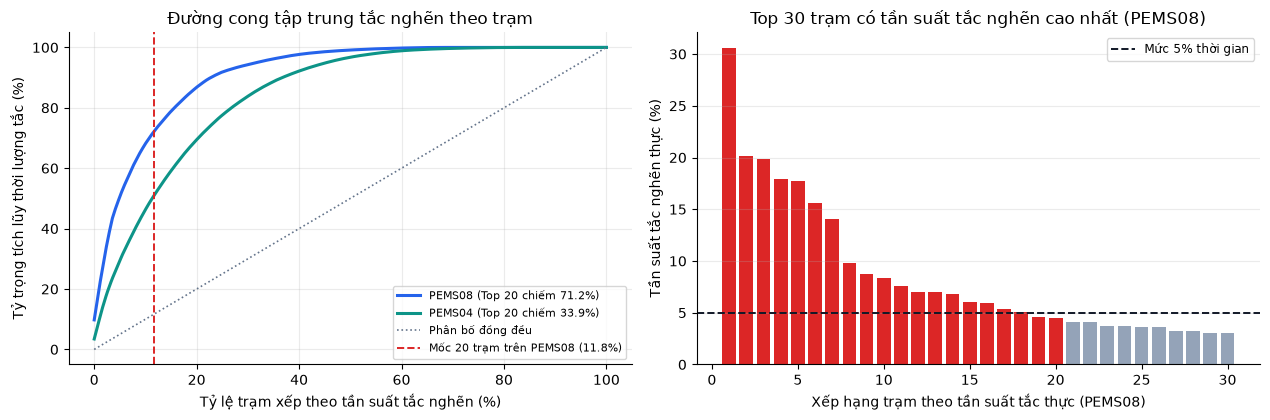

In [6]:
TOP_K = 20
is_cong = lambda a: (a[:, :, 2] < SPEED_TH) & (a[:, :, 1] >= OCC_TH)

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.3))
for nm, c in [("PEMS08", "#2563eb"), ("PEMS04", "#0d9488")]:
    d_arr = ds[nm]["data"]
    c_mat = is_cong(d_arr)
    freq_raw = c_mat.mean(axis=0)
    freq = np.sort(freq_raw)[::-1]
    cum = np.cumsum(freq) / max(freq.sum(), 1e-8) * 100.0
    top20_sh = 100.0 * freq[:TOP_K].sum() / freq.sum()
    print(f"{nm}: Tỷ lệ tắc thực chung={100*freq_raw.mean():.2f}% | Số trạm tắc >=5%: {(freq>=0.05).sum()}/{len(freq)} | Trạm <1%: {(freq<0.01).sum()}/{len(freq)} | Top {TOP_K} chiếm: {top20_sh:.1f}%")
    m_day = ((np.arange(len(d_arr)) % 288) // 12 >= 5) & ((np.arange(len(d_arr)) % 288) // 12 <= 23)
    t_joint = set(np.argsort(freq_raw)[::-1][:TOP_K])
    t_day = set(np.argsort(c_mat[m_day].mean(axis=0))[::-1][:TOP_K])
    print(f"  -> Độ vững Top {TOP_K} ({nm}): trùng {len(t_joint & t_day)}/{TOP_K} (khi giới hạn khung 05-23h)")
    axes[0].plot(np.linspace(0, 100, len(freq)), cum, color=c, lw=2.2, label=f"{nm} (Top 20 chiếm {top20_sh:.1f}%)")
    if nm == "PEMS08":
        axes[1].bar(range(1, 31), freq[:30] * 100.0, color=["#dc2626" if i < TOP_K else "#94a3b8" for i in range(30)])

axes[0].plot([0, 100], [0, 100], color="#64748b", ls=":", lw=1.2, label="Phân bố đồng đều")
axes[0].axvline(100 * TOP_K / 170, color="#dc2626", ls="--", lw=1.4, label="Mốc 20 trạm trên PEMS08 (11.8%)")
axes[0].set(xlabel="Tỷ lệ trạm xếp theo tần suất tắc nghẽn (%)", ylabel="Tỷ trọng tích lũy thời lượng tắc (%)",
            title="Đường cong tập trung tắc nghẽn theo trạm")
axes[0].legend(frameon=True, fontsize=8.2); axes[0].grid(alpha=0.25)

axes[1].axhline(5.0, color="#111827", ls="--", lw=1.4, label="Mức 5% thời gian")
axes[1].set(xlabel="Xếp hạng trạm theo tần suất tắc thực (PEMS08)", ylabel="Tần suất tắc nghẽn thực (%)",
            title="Top 30 trạm có tần suất tắc nghẽn cao nhất (PEMS08)")
axes[1].legend(frameon=True, fontsize=8.5); axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_bottleneck_concentration.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Tác dụng của việc tách riêng Top 20 điểm nghẽn theo tiêu chí kép):**
>
> * **Tập trung vào phần lớn rủi ro mạng lưới (Nguyên lý Pareto):** Trên `PEMS08` (`N = 170`), theo tiêu chí tắc nghẽn thực `(Speed < 40 & Occ ≥ 0.15)`, chỉ có **`18` trạm (`10.6%`)** bị tắc từ `5%` tổng thời gian trở lên (đầu bảng `N22` kẹt tới `30.6%` thời gian), và nhóm **Top `20` trạm gánh tới `71.2%` tổng thời lượng tắc nghẽn thực của cả mạng lưới**. Trên mạng `PEMS04` (`307` trạm) tắc nghẽn phân tán rộng hơn (`62/307` trạm tắc `≥ 5%`) nên Top 20 trạm gánh **`33.9%`**.
>
> * **Tránh mất cân bằng lớp nghiêm trọng khi đánh giá mô hình:** Toàn mạng `PEMS08` có tỷ lệ tắc thực trung bình chỉ `1.84%`, và có tới **`125/170` trạm (`73.5%`) hầu như không bao giờ tắc (`< 1%` thời gian)**. Nếu chấm điểm dự báo ùn tắc dàn trải trên cả 170 nút, các nút luôn thông thoáng sẽ làm loãng thước đo (dự báo "không tắc" mọi lúc vẫn cho độ chính xác giả tạo).
>
> * **Phân tách vai trò "nút nguồn cung cấp tín hiệu" và "nút mục tiêu dự báo":** Trong giai đoạn mô hình hóa dựa trên đồ thị, **toàn bộ `170` trạm vẫn được giữ nguyên làm nút đồ thị đầu vào** để truyền thông tin lưu lượng, độ chiếm dụng và vận tốc từ các trạm đầu nguồn lân cận; còn **Top `20` điểm nghẽn** là tập nút trọng tâm để đánh giá dự báo cảnh báo sớm.
>
> * **Độ vững của danh sách Top 20 theo thời gian trong ngày:** Kiểm tra độ nhạy xác nhận danh sách Top 20 điểm nghẽn thực **trùng tuyệt đối `20/20` (`100%`)** khi giới hạn riêng khung vận hành `05–23h` trên cả `PEMS08` lẫn `PEMS04`.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi đặt Top 20 điểm nghẽn này lên sơ đồ mạng lưới đường bộ, chúng có phải là các nút có độ trung tâm cấu trúc tĩnh (`Degree`, `Betweenness`, `Closeness`) cao nhất hay không?

---
## 5. Giải phẫu cấu trúc đồ thị mạng lưới & Bản đồ điểm nghẽn

Khi đã định danh được Top 20 điểm nghẽn, bước tiếp theo là đặt chúng lên **cấu trúc đồ thị đường bộ** để kiểm tra: *các điểm nghẽn này nằm ở vị trí nào trên mạng lưới, và các chỉ số cấu trúc tĩnh (`Degree`, `Weighted Betweenness Centrality`, `Closeness Centrality`) giải thích được bao nhiêu về mức độ tắc nghẽn?*

In [7]:
metrics_all = {}
for name in ["PEMS08", "PEMS04"]:
    G, arr = ds[name]["G"], ds[name]["data"]
    betw = nx.betweenness_centrality(G, weight="cost", normalized=True)
    close = nx.closeness_centrality(G, distance="cost")
    in_d, out_d = dict(G.in_degree()), dict(G.out_degree())
    cong, mean_spd = is_cong(arr).mean(axis=0), arr[:, :, 2].mean(axis=0)

    df = pd.DataFrame([{
        "node_id": n, "betweenness": betw[n], "closeness": close[n],
        "in_degree": in_d[n], "out_degree": out_d[n], "degree": in_d[n] + out_d[n],
        "congestion_freq": float(cong[n]), "mean_speed": float(mean_spd[n]),
    } for n in range(arr.shape[1])])
    top_ids = df.sort_values(["congestion_freq", "degree", "betweenness"], ascending=False).head(TOP_K)["node_id"]
    df["is_bottleneck"] = df["node_id"].isin(top_ids)
    metrics_all[name] = df
    df.to_csv(OUT_DIR / f"{name}_bottlenecks.csv", index=False)

    Ge = G.copy()
    for r in df.itertuples(index=False):
        Ge.nodes[r.node_id].update({"betweenness": float(r.betweenness), "degree": int(r.degree),
                                    "congestion_freq": float(r.congestion_freq), "is_bottleneck": bool(r.is_bottleneck)})
    nx.write_gexf(Ge, OUT_DIR / f"{name}_network.gexf")

    r_deg, p_deg = spearmanr(df["congestion_freq"], df["degree"])
    r_bet, p_bet = spearmanr(df["congestion_freq"], df["betweenness"])
    r_cls, p_cls = spearmanr(df["congestion_freq"], df["closeness"])
    print(f"{name}: Degree={r_deg:.3f} (p={p_deg:.4f}) | Betweenness={r_bet:.3f} (p={p_bet:.4f}) | Closeness={r_cls:.3f} (p={p_cls:.4f})")

metrics_all["PEMS08"].query("is_bottleneck").sort_values("congestion_freq", ascending=False).head(10).round(4)

PEMS08: Degree=0.185 (p=0.0156) | Betweenness=0.067 (p=0.3842) | Closeness=0.232 (p=0.0024)
PEMS04: Degree=0.127 (p=0.0266) | Betweenness=0.051 (p=0.3704) | Closeness=0.035 (p=0.5458)


,node_id,betweenness,closeness,in_degree,out_degree,degree,congestion_freq,mean_speed,is_bottleneck
22,22,0.0711,0.0003,4,4,8,0.3057,54.0542,True
14,14,0.0622,0.0003,4,5,9,0.2011,56.0674,True
13,13,0.0476,0.0003,4,5,9,0.1985,56.0379,True
9,9,0.0000,0.0000,0,3,3,0.1797,59.7340,True
4,4,0.0111,0.0003,3,3,6,0.1770,56.1833,True
65,65,0.0047,0.0000,1,2,3,0.1562,58.5667,True
128,128,0.0393,0.0003,3,2,5,0.1407,57.3352,True
7,7,0.0316,0.0003,4,2,6,0.0980,60.0007,True
41,41,0.0604,0.0004,5,3,8,0.0873,61.4016,True
47,47,0.0000,0.0000,0,1,1,0.0832,60.3048,True


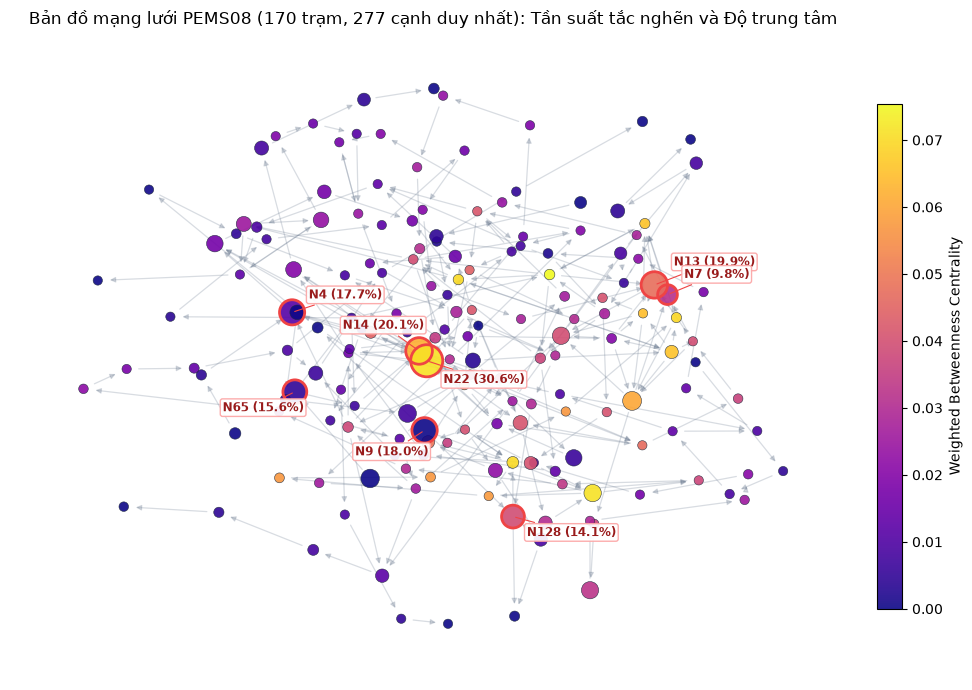

In [8]:
G8, df8 = ds["PEMS08"]["G"], metrics_all["PEMS08"]
fig, ax = plt.subplots(figsize=(10.5, 7.0))
pos = nx.spring_layout(G8, seed=SEED, k=0.42, iterations=100)
nodes = list(G8.nodes())
sizes = [45 + 1600 * df8.loc[n, "congestion_freq"] for n in nodes]

nx.draw_networkx_edges(G8, pos, ax=ax, alpha=0.25, width=0.9, edge_color="#64748b", arrows=True, arrowsize=8)
sc = nx.draw_networkx_nodes(G8, pos, nodelist=nodes, node_size=sizes, node_color=[df8.loc[n, "betweenness"] for n in nodes],
                            cmap="plasma", alpha=0.9, edgecolors="#1e293b", linewidths=0.4, ax=ax)
top8 = df8.query("is_bottleneck").sort_values("congestion_freq", ascending=False).head(8)
nx.draw_networkx_nodes(G8, pos, nodelist=top8["node_id"].tolist(),
                       node_size=[45 + 1600 * df8.loc[n, "congestion_freq"] for n in top8["node_id"]],
                       node_color="none", edgecolors="#ef4444", linewidths=2.0, ax=ax)

offsets = [(12, -16), (-55, 16), (14, 14), (-50, -18), (12, 10), (-52, -14), (10, -14), (12, 12)]
for r, (dx, dy) in zip(top8.itertuples(index=False), offsets):
    ax.annotate(f"N{r.node_id} ({r.congestion_freq*100:.1f}%)", pos[r.node_id], xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, fontweight="bold", color="#991b1b",
                arrowprops=dict(arrowstyle="-", color="#ef4444", lw=0.8),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#fca5a5", alpha=0.92))

fig.colorbar(sc, ax=ax, shrink=0.78, pad=0.02, label="Weighted Betweenness Centrality")
ax.set_title("Bản đồ mạng lưới PEMS08 (170 trạm, 277 cạnh duy nhất): Tần suất tắc nghẽn và Độ trung tâm")
ax.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_network_map_pems08.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Giải thích 3 cặp kiểm định p-value cho 3 chỉ số đồ thị trên 2 bộ dữ liệu):**
>
> * **Bậc kết nối (`Degree`):** Có tương quan thuận **ở mức yếu nhưng có ý nghĩa thống kê ($p < 0.05$)** với tần suất tắc nghẽn thực trên cả `PEMS08` (**$\rho = 0.185, p = 0.0156$**) và `PEMS04` (**$\rho = 0.127, p = 0.0266$**), cho thấy các nút giao có nhiều nhánh nhập/tách (ví dụ `N22`, `N14`, `N13` có 8–9 cạnh nối; đồ thị `PEMS08` có `277` cạnh có hướng duy nhất sau khi gộp `18` cạnh trùng từ `295` dòng CSV gốc) chịu rủi ro tắc nghẽn cao hơn nhẹ.
>
> * **Độ trung tâm cầu nối (`Weighted Betweenness Centrality`):** Không có tương quan đơn điệu có ý nghĩa thống kê trên cả `PEMS08` (**$\rho = 0.067, p = 0.3842$**) lẫn `PEMS04` (**$\rho = 0.051, p = 0.3704$**). Bằng chứng trực quan trên bản đồ là các trạm như `N9` (`18.0%`) hay `N65` (`15.6%`) có `Betweenness` rất thấp (màu tím tối) nhưng vẫn tắc nặng.
>
> * **Độ trung tâm gần (`Closeness Centrality`):** Có tương quan thuận yếu trên `PEMS08` (**$\rho = 0.232, p = 0.0024$**) nhưng **không lặp lại trên `PEMS04`** (**$\rho = 0.035, p = 0.5458$**) do mạng `PEMS04` trải dài dạng hành lang.
>
> * **Hàm ý:** Không một chỉ số cấu trúc tĩnh đơn lẻ nào đủ sức dự báo nhất quán điểm nghẽn trên mọi mạng lưới — ta cần chuyển sang phân tích động lực chuỗi thời gian giữa các trạm kết nối.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Trước thời điểm một điểm nghẽn rơi vào trạng thái tắc nghẽn thực (`Speed < 40 mph & Occ ≥ 0.15`), bộ ba biến `Lưu lượng – Độ chiếm dụng – Vận tốc` tại chính trạm đó biến đổi theo trình tự như thế nào?

---
## 6. Thống kê tiền tắc nghẽn & Tín hiệu cảnh báo sớm

### 6.1. Quỹ đạo pha tại điểm nghẽn trong 60 phút trước khi khởi phát tắc nghẽn
Từ nhận định ở Mục 5, ta chuyển sang phân tích động lực chuỗi thời gian: tách toàn bộ các sự cố khởi phát tắc nghẽn thực tại Top 20 điểm nghẽn của `PEMS08` (thời điểm trạm chuyển từ trạng thái chưa tắc sang thỏa mãn đồng thời `Speed < 40 mph & Occ ≥ 0.15`) và theo dõi quỹ đạo trung bình của `Lưu lượng`, `Độ chiếm dụng` và `Vận tốc` trong cửa sổ từ `t - 60 phút` đến `t + 10 phút`.

Số sự cố khởi phát (tắc thực): n=2034
  t=-60p: Flow=424.8 | Occ=0.145 | Speed=55.4
  t=-15p: Flow=433.9 | Occ=0.172 | Speed=49.7
  t=+0p: Flow=399.7 | Occ=0.254 | Speed=36.9


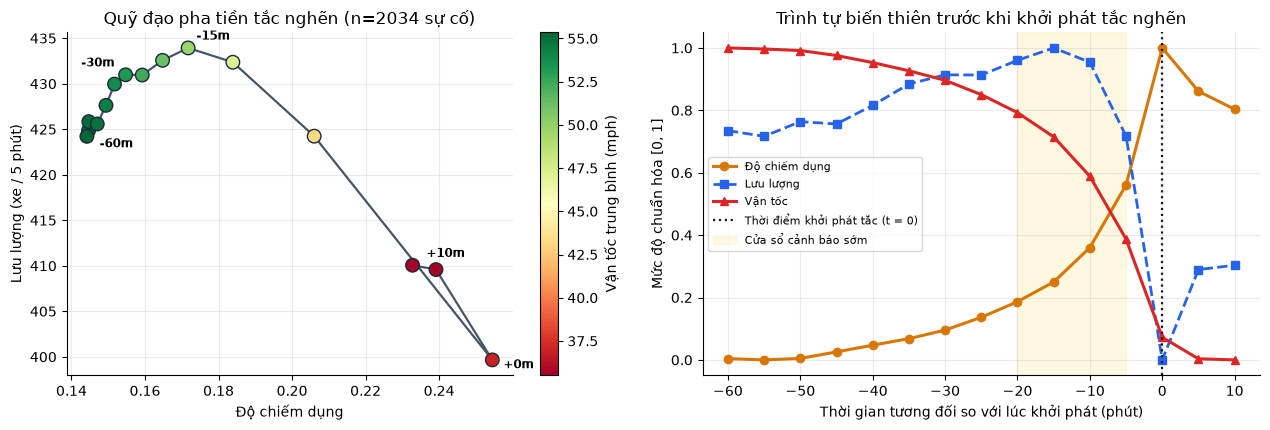

In [9]:
bn_nodes8 = metrics_all["PEMS08"].query("is_bottleneck")["node_id"].to_numpy()
pre, post = 12, 2
cg_mat = (d8[:, :, 2] < SPEED_TH) & (d8[:, :, 1] >= OCC_TH)
onsets = [(t, nid) for nid in bn_nodes8 for t in range(pre, d8.shape[0] - post)
          if not cg_mat[t - 1, nid] and cg_mat[t, nid] and (~cg_mat[t - pre : t, nid]).mean() >= 0.7]

traj = np.array([d8[t - pre : t + post + 1, nid, :] for t, nid in onsets])
m_flow, m_occ, m_spd = traj[:, :, 0].mean(axis=0), traj[:, :, 1].mean(axis=0), traj[:, :, 2].mean(axis=0)
rel_m = np.arange(-pre, post + 1) * 5
print(f"Số sự cố khởi phát (tắc thực): n={len(onsets)}")
for idx in [0, 9, 12]:
    print(f"  t={rel_m[idx]:+d}p: Flow={m_flow[idx]:.1f} | Occ={m_occ[idx]:.3f} | Speed={m_spd[idx]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4))
sc = axes[0].scatter(m_occ, m_flow, c=m_spd, cmap="RdYlGn", s=95, edgecolors="#1e293b", zorder=4)
axes[0].plot(m_occ, m_flow, color="#475569", lw=1.6, zorder=3)
for idx, (dx, dy) in zip([0, 6, 9, 12, 14], [(8, -12), (-32, 6), (6, 6), (8, -6), (10, 6)]):
    axes[0].annotate(f"{rel_m[idx]:+d}m", (m_occ[idx], m_flow[idx]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, fontweight="bold")
fig.colorbar(sc, ax=axes[0], label="Vận tốc trung bình (mph)")
axes[0].set(xlabel="Độ chiếm dụng", ylabel="Lưu lượng (xe / 5 phút)", title=f"Quỹ đạo pha tiền tắc nghẽn (n={len(onsets)} sự cố)")
axes[0].grid(alpha=0.25)

norm = lambda v: (v - v.min()) / max(v.max() - v.min(), 1e-6)
axes[1].plot(rel_m, norm(m_occ), "o-", color="#d97706", lw=2.2, label="Độ chiếm dụng")
axes[1].plot(rel_m, norm(m_flow), "s--", color="#2563eb", lw=2.0, label="Lưu lượng")
axes[1].plot(rel_m, norm(m_spd), "^-", color="#dc2626", lw=2.2, label="Vận tốc")
axes[1].axvline(0, color="#111827", ls=":", lw=1.6, label="Thời điểm khởi phát tắc (t = 0)")
axes[1].axvspan(-20, -5, color="#fef3c7", alpha=0.55, label="Cửa sổ cảnh báo sớm")
axes[1].set(xlabel="Thời gian tương đối so với lúc khởi phát (phút)", ylabel="Mức độ chuẩn hóa [0, 1]",
            title="Trình tự biến thiên trước khi khởi phát tắc nghẽn")
axes[1].legend(frameon=True, fontsize=8.2); axes[1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_phase_trajectory.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Giải thích biểu đồ quỹ đạo pha trung bình gộp, `n = 2.034` sự cố):**
>
> * **Biểu đồ bên trái (Quỹ đạo pha `Độ chiếm dụng – Lưu lượng`):** Tính trung bình gộp trên `2.034` lần chuyển pha tại Top 20 điểm nghẽn (điều kiện ≥ 70% khoảng 60 phút trước đó chưa rơi vào tắc nghẽn thực), từ `t = -60 phút` đến `t = -15 phút`, lưu lượng tăng từ `~424.8` lên đỉnh `~433.9 xe/5 phút` trong khi mặt đường tích tụ xe (`Occupancy` tăng từ `0.145` lên `0.172`, `Speed` giảm từ `55.4` xuống `49.7 mph`). Sau mốc **`-15 phút`**, hệ thống bước vào pha sụp đổ ngược chiều: `Lưu lượng` giảm nhanh xuống `~399.7 xe/5 phút`, còn `Độ chiếm dụng` tăng vọt lên `0.254` và vận tốc tụt xuống `36.9 mph` tại `t = 0`.
>
> * **Biểu đồ bên phải (Trình tự chuẩn hóa) & Giới hạn diễn giải:** Trong cửa sổ **`t - 20` đến `t - 5` phút**, `Độ chiếm dụng` tăng dựng đứng trước khi dòng xe vỡ pha tại `t = 0`. Tuy nhiên, đây mới là **xu hướng trung bình của các ca đã chắc chắn xảy ra tắc nghẽn** — chưa định lượng được tỷ lệ cảnh báo giả ở các ca bình thường và chưa xét từng sự cố riêng lẻ (nội dung này sẽ được kiểm chứng bằng mô hình phân loại ở Bước 04).
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Tín hiệu tiền tắc nghẽn có chỉ nằm tại chính điểm nghẽn hay đã xuất hiện sớm hơn ở các **trạm đầu nguồn nối trực tiếp** phía trước?

### 6.2. Tín hiệu cảnh báo sớm từ các trạm đầu nguồn trên đồ thị
Nếu tại chính điểm nghẽn đã có dấu hiệu tiền tắc nghẽn trước 5–20 phút, câu hỏi tiếp theo là: **liệu các trạm đầu nguồn nối trực tiếp (`u → điểm nghẽn`) có truyền tín hiệu cảnh báo sớm hơn và đặc hiệu hơn các trạm ngẫu nhiên không nối hay không?** Ta kiểm chứng qua phân tích tương quan trễ (`0–60 phút`).

 Độ trễ (phút)  Gốc: Đầu nguồn  Gốc: Ngẫu nhiên  p (gốc)  Phần dư: Đầu nguồn  Phần dư: Ngẫu nhiên  p (phần dư)
             0         -0.5520          -0.4894   0.0568             -0.3029              -0.2453       0.0840
             5         -0.5545          -0.4921   0.0571             -0.3083              -0.2483       0.0715
            10         -0.5553          -0.4944   0.0613             -0.3109              -0.2513       0.0712
            15         -0.5554          -0.4962   0.0671             -0.3126              -0.2537       0.0723
            20         -0.5550          -0.4976   0.0738             -0.3141              -0.2558       0.0723
            30         -0.5521          -0.4993   0.0966             -0.3152              -0.2599       0.0854
            45         -0.5415          -0.4972   0.1570             -0.3109              -0.2614       0.1210
            60         -0.5258          -0.4903   0.2560             -0.3028              -0.2597       0.1741


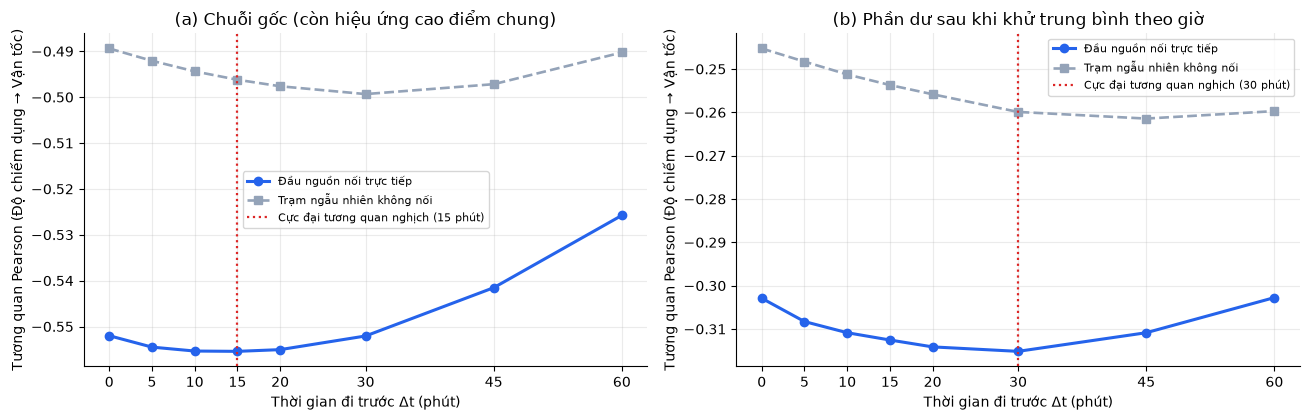

In [10]:
G8 = ds["PEMS08"]["G"]
lags = [0, 1, 2, 3, 4, 6, 9, 12]
rng = np.random.default_rng(SEED)

# Khử trung bình theo khung giờ trong ngày (t % 288) để tách nhiễu nhịp cao điểm chung toàn mạng
tod_occ = d8.reshape(-1, 288, d8.shape[1], 3).mean(axis=0)[:, :, 1]
tod_spd = d8.reshape(-1, 288, d8.shape[1], 3).mean(axis=0)[:, :, 2]
res_occ = (d8.reshape(-1, 288, d8.shape[1], 3)[:, :, :, 1] - tod_occ).reshape(-1, d8.shape[1])
res_spd = (d8.reshape(-1, 288, d8.shape[1], 3)[:, :, :, 2] - tod_spd).reshape(-1, d8.shape[1])

# Cố định tập đầu nguồn duy nhất và một tập ngẫu nhiên không nối duy nhất xuyên suốt các độ trễ
pairs = []
for bn in bn_nodes8:
    ups = sorted(u for u in G8.predecessors(int(bn)) if u != bn)
    if not ups:
        continue
    pool = [u for u in range(d8.shape[1]) if u != bn and u not in ups]
    pairs.append((int(bn), ups, rng.choice(pool, size=len(ups), replace=False).tolist()))

lag_rows = []
for lag in lags:
    up_c, rnd_c, ru_c, rr_c = [], [], [], []
    t_end = d8.shape[0] - lag if lag > 0 else d8.shape[0]
    for bn, ups, rnd in pairs:
        up_c.append(np.corrcoef(d8[:t_end, ups, 1].mean(axis=1), d8[lag:, bn, 2])[0, 1])
        rnd_c.append(np.corrcoef(d8[:t_end, rnd, 1].mean(axis=1), d8[lag:, bn, 2])[0, 1])
        ru_c.append(np.corrcoef(res_occ[:t_end, ups].mean(axis=1), res_spd[lag:, bn])[0, 1])
        rr_c.append(np.corrcoef(res_occ[:t_end, rnd].mean(axis=1), res_spd[lag:, bn])[0, 1])
    lag_rows.append({
        "Độ trễ (phút)": lag * 5,
        "Gốc: Đầu nguồn": float(np.mean(up_c)), "Gốc: Ngẫu nhiên": float(np.mean(rnd_c)),
        "p (gốc)": float(ttest_rel(up_c, rnd_c).pvalue),
        "Phần dư: Đầu nguồn": float(np.mean(ru_c)), "Phần dư: Ngẫu nhiên": float(np.mean(rr_c)),
        "p (phần dư)": float(ttest_rel(ru_c, rr_c).pvalue),
    })

lag_df = pd.DataFrame(lag_rows)
print(lag_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.3))
cfg = [(axes[0], "Gốc: Đầu nguồn", "Gốc: Ngẫu nhiên", "(a) Chuỗi gốc (còn hiệu ứng cao điểm chung)"),
       (axes[1], "Phần dư: Đầu nguồn", "Phần dư: Ngẫu nhiên", "(b) Phần dư sau khi khử trung bình theo giờ")]
for ax, c1, c2, ttl in cfg:
    ax.plot(lag_df["Độ trễ (phút)"], lag_df[c1], "o-", color="#2563eb", lw=2.2, label="Đầu nguồn nối trực tiếp")
    ax.plot(lag_df["Độ trễ (phút)"], lag_df[c2], "s--", color="#94a3b8", lw=1.9, label="Trạm ngẫu nhiên không nối")
    best_m = int(lag_df.loc[lag_df[c1].idxmin(), "Độ trễ (phút)"])
    ax.axvline(best_m, color="#dc2626", ls=":", lw=1.6, label=f"Cực đại tương quan nghịch ({best_m} phút)")
    ax.set(xlabel="Thời gian đi trước Δt (phút)", ylabel="Tương quan Pearson (Độ chiếm dụng → Vận tốc)",
           xticks=lag_df["Độ trễ (phút)"], title=ttl)
    ax.legend(frameon=True, fontsize=8.0); ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_upstream_lag_correlation.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Giải thích biểu đồ tương quan trễ đầu nguồn & Giới hạn kiểm định tuyến tính):**
>
> * **Hình `(a)` — Ảnh hưởng của nhịp cao điểm chung:** Trên chuỗi gốc, ngay cả nhóm **trạm ngẫu nhiên không kết nối** cũng đạt `r ≈ -0.49` đến `-0.50` ở `0–30 phút` (chênh với đầu nguồn trực tiếp `r ≈ -0.552` đến `-0.555` khoảng `0.059–0.063`). Nguyên nhân là giờ cao điểm sáng/chiều diễn ra đồng loạt trên toàn mạng lưới khiến hầu hết các trạm biến động cùng pha.
>
> * **Hình `(b)` — Khi khử nhịp trung bình theo giờ trong ngày:** Độ lớn tương quan nền giảm một nửa còn `r ≈ -0.245` đến `-0.261` (ngẫu nhiên) so với `-0.303` đến `-0.315` (đầu nguồn trực tiếp, đạt đỉnh nghịch ở **`30 phút`**), giữ khoảng cách dương ổn định hơn hẳn trước nhưng khi kiểm định `t-test` ghép cặp trên tập điểm nghẽn có cạnh đầu nguồn thì **`p = 0.071–0.174` (`> 0.05`)**.
>
> * **Hàm ý cho mô hình hóa:** Phân tích tương quan tuyến tính gộp toàn chuỗi **chưa đủ để chứng minh có ý nghĩa thống kê** sự lan truyền từ đầu nguồn do nhiễu chu kỳ chung và ngưỡng chuyển pha phi tuyến. Do đó, Mục `6.3` phải lọc riêng thời điểm đường sắp khởi phát tắc nghẽn thực (`chưa tắc → tắc thực`) và Bước 04 cần dùng mô hình học phi tuyến trên đồ thị để kiểm chứng thực tế.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Nếu bỏ đi các khoảng đường đang tắc sẵn để chỉ giữ lại đúng thời điểm **đường chưa tắc nghẽn**, thì mức nền hiện tại và tốc độ biến thiên gần nhất có báo hiệu được nguy cơ sắp chuyển sang tắc nghẽn thực (`Speed < 40 & Occ ≥ 0.15`) hay không?

### 6.3. Đặc trưng tốc độ biến thiên trước lúc khởi phát tắc nghẽn

Phần 6.2 xét tương quan trên toàn bộ chuỗi thời gian. Tuy nhiên, bài toán cảnh báo sớm chỉ thực sự có ý nghĩa khi tại thời điểm hiện tại $t$ đoạn đường **vẫn chưa tắc nghẽn** (không thỏa mãn đồng thời `Vận tốc < 40 mph & Độ chiếm dụng ≥ 0.15`) nhưng sắp rơi vào tắc nghẽn thực sau $\Delta t$ phút (`Vận tốc(t + Δt) < 40 mph` và `Độ chiếm dụng(t + Δt) ≥ 0.15`).

Bước này tạo thêm nhóm **đặc trưng tốc độ biến thiên** trong quá khứ gần ($\Delta x_t = x_t - x_{t-k}$ với $k \in \{5, 15\}$ phút — đo mức thay đổi tức thời của lưu lượng, độ chiếm dụng và vận tốc tại cả điểm nghẽn lẫn trạm đầu nguồn) để kiểm định mức độ tương quan với biến cố **sắp khởi phát tắc nghẽn thực** ở tầm dự báo $\Delta t \in \{5, 10, 15, 20\}$ phút.

                                 5 phút  10 phút  15 phút  20 phút
Vận tốc(t)                      -0.2946  -0.3198  -0.3228  -0.3192
Độ chiếm dụng(t)                 0.2534   0.2841   0.2956   0.2989
Độ chiếm dụng đầu nguồn(t)       0.1107   0.1338   0.1505   0.1617
Δ Vận tốc (15p)                 -0.0983  -0.1083  -0.1013  -0.0916
Δ Vận tốc (5p)                  -0.0888  -0.1039  -0.0985  -0.0878
Δ Độ chiếm dụng (15p)            0.0799   0.0889   0.0813   0.0721
Δ Độ chiếm dụng (5p)             0.0686   0.0771   0.0780   0.0678
Δ Lưu lượng (15p)               -0.0019   0.0101   0.0174   0.0200
Δ Độ chiếm dụng đầu nguồn (15p)  0.0007   0.0060   0.0093   0.0150
Tỷ lệ nền khởi phát: 10p=1.56% | 20p=2.34%
Up_Occ(t) Top10% (>= 0.133) vs Bot10% (<= 0.022) -> 20p: 7.58% vs 0.02% (433.9x)
ΔVận tốc(15p) Bot10% (<= -3.20) vs Đi ngang (|Δ|<1) -> 10p: 7.08% vs 0.42% (16.7x)


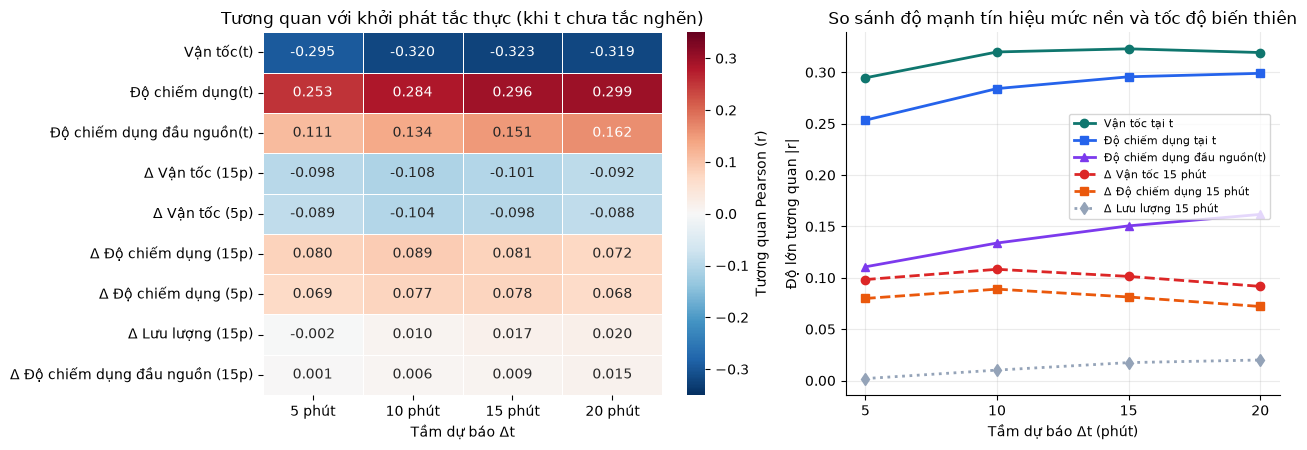

In [11]:
leads_min = [5, 10, 15, 20]
max_step = max(leads_min) // 5
k_pad, end = 3, d8.shape[0] - max_step
t_slice = slice(k_pad, end)

feat_cols = ["Vận tốc(t)", "Độ chiếm dụng(t)", "Độ chiếm dụng đầu nguồn(t)",
             "Δ Vận tốc (15p)", "Δ Vận tốc (5p)", "Δ Độ chiếm dụng (15p)",
             "Δ Độ chiếm dụng (5p)", "Δ Lưu lượng (15p)", "Δ Độ chiếm dụng đầu nguồn (15p)"]
buckets = {name: [] for name in feat_cols}
targets = {m: [] for m in leads_min}

for bn in bn_nodes8:
    ups = sorted(u for u in G8.predecessors(int(bn)) if u != bn)
    if not ups:
        continue
    flw, occ, spd = d8[:, bn, 0], d8[:, bn, 1], d8[:, bn, 2]
    up_occ = d8[:, ups, 1].mean(axis=1)
    cg = (spd < SPEED_TH) & (occ >= OCC_TH)
    free = ~cg[t_slice]
    diff = lambda arr, s: (arr[t_slice] - arr[k_pad - s : end - s])[free]

    vals = {
        "Vận tốc(t)": spd[t_slice][free],
        "Độ chiếm dụng(t)": occ[t_slice][free],
        "Độ chiếm dụng đầu nguồn(t)": up_occ[t_slice][free],
        "Δ Vận tốc (15p)": diff(spd, 3),
        "Δ Vận tốc (5p)": diff(spd, 1),
        "Δ Độ chiếm dụng (15p)": diff(occ, 3),
        "Δ Độ chiếm dụng (5p)": diff(occ, 1),
        "Δ Lưu lượng (15p)": diff(flw, 3),
        "Δ Độ chiếm dụng đầu nguồn (15p)": diff(up_occ, 3),
    }
    for k_name, arr in vals.items():
        buckets[k_name].append(arr)
    for m in leads_min:
        step = m // 5
        targets[m].append(cg[k_pad + step : end + step][free].astype(float))

X_roc = {k_name: np.concatenate(v) for k_name, v in buckets.items()}
corr_roc = pd.DataFrame({f"{m} phút": [np.corrcoef(X_roc[f], np.concatenate(targets[m]))[0, 1] for f in feat_cols]
                         for m in leads_min}, index=feat_cols)
print(corr_roc.round(4).to_string())
y10, y20 = np.concatenate(targets[10]), np.concatenate(targets[20])
uo, ds15 = X_roc["Độ chiếm dụng đầu nguồn(t)"], X_roc["Δ Vận tốc (15p)"]
q90_uo, q10_uo = np.quantile(uo, 0.90), np.quantile(uo, 0.10)
q10_ds = np.quantile(ds15, 0.10)
r_uo_hi, r_uo_lo = y20[uo >= q90_uo].mean(), y20[uo <= q10_uo].mean()
r_ds_hi, r_ds_calm = y10[ds15 <= q10_ds].mean(), y10[(ds15 > -1) & (ds15 < 1)].mean()
print(f"Tỷ lệ nền khởi phát: 10p={100*y10.mean():.2f}% | 20p={100*y20.mean():.2f}%")
print(f"Up_Occ(t) Top10% (>= {q90_uo:.3f}) vs Bot10% (<= {q10_uo:.3f}) -> 20p: {100*r_uo_hi:.2f}% vs {100*r_uo_lo:.2f}% ({r_uo_hi/max(r_uo_lo, 1e-8):.1f}x)")
print(f"ΔVận tốc(15p) Bot10% (<= {q10_ds:.2f}) vs Đi ngang (|Δ|<1) -> 10p: {100*r_ds_hi:.2f}% vs {100*r_ds_calm:.2f}% ({r_ds_hi/max(r_ds_calm, 1e-8):.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6), gridspec_kw={"width_ratios": [1.15, 1.0]})
sns.heatmap(corr_roc, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-0.35, vmax=0.35,
            linewidths=0.5, ax=axes[0], cbar_kws={"label": "Tương quan Pearson (r)"})
axes[0].set_title("Tương quan với khởi phát tắc thực (khi t chưa tắc nghẽn)")
axes[0].set_xlabel("Tầm dự báo Δt")

curve_cfg = [
    ("Vận tốc(t)", "o-", "#0f766e", "Vận tốc tại t"),
    ("Độ chiếm dụng(t)", "s-", "#2563eb", "Độ chiếm dụng tại t"),
    ("Độ chiếm dụng đầu nguồn(t)", "^-", "#7c3aed", "Độ chiếm dụng đầu nguồn(t)"),
    ("Δ Vận tốc (15p)", "o--", "#dc2626", "Δ Vận tốc 15 phút"),
    ("Δ Độ chiếm dụng (15p)", "s--", "#ea580c", "Δ Độ chiếm dụng 15 phút"),
    ("Δ Lưu lượng (15p)", "d:", "#94a3b8", "Δ Lưu lượng 15 phút"),
]
for fname, marker, color, lbl in curve_cfg:
    axes[1].plot(leads_min, corr_roc.loc[fname].abs(), marker, color=color, lw=2.0, label=lbl)
axes[1].set(xlabel="Tầm dự báo Δt (phút)", ylabel="Độ lớn tương quan |r|", xticks=leads_min,
            title="So sánh độ mạnh tín hiệu mức nền và tốc độ biến thiên")
axes[1].legend(frameon=True, fontsize=7.8, loc="center right", bbox_to_anchor=(0.99, 0.63)); axes[1].grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIG_DIR / "nb03_rate_of_change_correlation.png", bbox_inches="tight")
plt.show()

> **Nhận xét (Vai trò bổ trợ của đặc trưng tốc độ biến thiên và lý do cần kiểm định Risk Ratio):**
>
> * **Nhóm biến mức nền tại $t$ giữ tín hiệu mạnh nhất:** Khi điểm nghẽn chưa tắc nghẽn, `Vận tốc(t)` (`r ≈ -0.295` đến `-0.323`) và `Độ chiếm dụng(t)` (`r ≈ +0.253` đến `+0.299`) mang tương quan mạnh nhất với nguy cơ khởi phát tắc nghẽn thực. Đáng chú ý, `Độ chiếm dụng đầu nguồn(t)` là **tín hiệu duy nhất tăng đơn điệu theo tầm dự báo** (`r = +0.111` ở 5 phút → `+0.134` ở 10 phút → `+0.151` ở 15 phút → **`+0.162` ở 20 phút**), phù hợp giả thuyết dòng xe dồn ứ từ đầu nguồn cần thời gian lan truyền tới điểm nghẽn.
>
> * **Nhóm tốc độ biến thiên cục bộ đạt đỉnh tại `10 phút`:** Hai đặc trưng biến thiên tại chỗ là `Δ Vận tốc (15p)` (`r = -0.108`) và `Δ Độ chiếm dụng (15p)` (`r = +0.089`) đạt cực đại tương quan tại tầm `10 phút` — nghĩa là khi trạm chưa tắc nhưng tốc độ đang sụt nhanh và độ chiếm dụng đang dâng đột ngột trong 15 phút gần nhất thì xác suất sắp kẹt tăng rõ rệt.
>
> * **Lưu lượng, biến thiên thô đầu nguồn và giới hạn:** `Δ Lưu lượng (15p)` (`|r| ≤ 0.020`) và hiệu số thô `Δ Độ chiếm dụng đầu nguồn (15p)` (`r ≤ 0.015`) tương quan rất yếu do tính đa trị của lưu lượng và nhiễu ngắn hạn từng 5 phút.
>
> * **Lý do hệ số tương quan tuyến tính `r` khiêm tốn nhưng tín hiệu phân tách cực mạnh (`Risk Ratio`):** Do chỉ lọc các thời điểm chưa tắc nghẽn, tỷ lệ nền sắp khởi phát tắc thực là một **sự kiện hiếm** (`1.56%` ở tầm 10 phút và `2.34%` ở tầm 20 phút), khiến hệ số tương quan nhị phân `Pearson r` bị nén mạnh về mặt toán học. Khi kiểm chứng trực tiếp bằng xác suất có điều kiện tại tầm `10–20 phút`: ở nhóm `Độ chiếm dụng đầu nguồn(t)` thuộc 10% cao nhất (`≥ 0.133`), xác suất xảy ra tắc thực sau 20 phút tăng vọt lên **`7.58%`** so với chỉ **`0.02%`** ở 10% thấp nhất (`≤ 0.022`, **gấp `433.9 lần`**); tương tự, khi `Δ Vận tốc (15p)` rơi vào 10% tụt sâu nhất (`≤ -3.20`), xác suất sắp tắc trong 10 phút đạt **`7.08%`** so với **`0.42%`** khi vận tốc đi ngang (`|Δ| < 1 mph`, **gấp `16.7 lần`**). Đây là cơ sở định lượng vững chắc để Bước 04 kết hợp đồng thời mức nền 3 biến, biến thiên tốc độ và thông tin đồ thị đầu nguồn trong các mô hình phi tuyến.

---
## 7. Tổng kết Khám phá & Chuyển tiếp sang Bước Mô hình hóa

Tổng hợp toàn bộ mạch bằng chứng định lượng từ Mục 2 đến Mục 6:

1. **Tính chu kỳ ngày – tuần & phân hóa cục bộ:** Hệ thống vận hành theo chu kỳ lặp rõ nét với hai đỉnh cao điểm sáng/chiều vào các ngày làm việc (`Thứ 2 – Thứ 6`) và suy giảm rõ rệt vào hai ngày cuối tuần (`day % 7` thuộc `[1, 2]` tương ứng `Thứ 7 – Chủ nhật` tính từ mốc `01/07/2016` là `Thứ 6`). Đường phân vị 5% vận tốc liên tục lao dốc xuống dưới `40 mph` trong khi trung vị toàn mạng vẫn ổn định quanh `60–67 mph`.

2. **Xét đồng thời cả 3 biến để chốt tiêu chí tắc nghẽn thực sự:** Trên sơ đồ cơ bản giao thông, khi vượt `Occupancy = 0.20`, lưu lượng suy giảm và vận tốc tụt từ `50.1 mph` xuống `35.7` rồi `24.9 mph`. Kết hợp đồng thời `Vận tốc < 40 mph` và `Độ chiếm dụng ≥ 0.15` loại bỏ được `6.765` điểm chạy chậm mật độ thấp (`Occ < 0.15`, `Flow P5–P25 = 30–77`), trong khi giữ `Lưu lượng` (vốn phi đơn điệu, tụt xuống `P25 = 239` ở pha tắc cứng `Occ ≥ 0.30`) làm biến kiểm chứng vật lý và đặc trưng đầu vào. Định nghĩa **`(Speed < 40 mph) & (Occ ≥ 0.15)`** được chốt thống nhất từ Mục 3.1.

3. **Phân bố Ban ngày – Ban đêm theo tiêu chí 3 biến:** Ban ngày (`06–21h`) chiếm tới **`97.28%`** (`54.330` điểm, `2.68%`) tổng thời lượng tắc thực trên `PEMS08` (gộp khung `05–23h` đạt **`99.56%`**). Ngược lại, khung đêm khuya (`00–04h`) hầu như không tắc — chỉ ghi nhận **`243` điểm (`0.04%` khung giờ, chiếm `0.44%` toàn mạng)**.

4. **Tập trung điểm nghẽn theo nguyên lý Pareto & độ vững Top 20:** Trên `PEMS08`, theo tiêu chí tắc thực, chỉ `18 / 170` trạm tắc `≥ 5%` thời gian nhưng **Top 20 trạm gánh tới `71.2%` tổng thời lượng tắc nghẽn thực** (trên `PEMS04` là **`33.9%`**). Danh sách Top 20 giữ mức trùng tuyệt đối **`20 / 20`** (`100%`) khi giới hạn khung giờ `05–23h` trên cả hai mạng.

5. **Hạn chế của 3 chỉ số cấu trúc đồ thị tĩnh:** Bậc kết nối (`Degree`) tương quan thuận yếu có ý nghĩa với tần suất tắc thực (`ρ = 0.185, p = 0.0156` trên `PEMS08`; `ρ = 0.127, p = 0.0266` trên `PEMS04`), `Weighted Closeness` chỉ có ý nghĩa trên `PEMS08` (`ρ = 0.232, p = 0.0024`) nhưng mất ý nghĩa trên `PEMS04` (`ρ = 0.035, p = 0.5458`), còn `Weighted Betweenness Centrality` hoàn toàn không có ý nghĩa (`p = 0.3842` và `0.3704`) — chứng tỏ hình học tĩnh không đủ dự báo tắc nghẽn nếu thiếu trạng thái động.

6. **Quỹ đạo tiền tắc nghẽn, tín hiệu đầu nguồn & Risk Ratio:** Quỹ đạo gộp (`n = 2.034` sự cố) chứng minh `Lưu lượng` đạt đỉnh `433.9` ở `-15p` rồi sụp giảm về `399.7` khi `Độ chiếm dụng` vọt lên `0.254` tại `t = 0`. Trước thời điểm khởi phát, `Độ chiếm dụng đầu nguồn(t)` là tín hiệu duy nhất tăng đơn điệu theo tầm dự báo (`r = +0.111 → +0.162`), còn `Δ Vận tốc (15p)` (`r = -0.108`) đạt đỉnh ở `10 phút`. Xét theo xác suất có điều kiện: top 10% `Độ chiếm dụng đầu nguồn(t)` (`≥ 0.133`) đẩy nguy cơ tắc thực sau 20 phút lên **`7.58%`** vs **`0.02%`** ở đáy 10% (**gấp `433.9 lần`**), và `Δ Vận tốc (15p)` tụt sâu nhất đẩy nguy cơ sau 10 phút lên **`7.08%`** vs **`0.42%`** (**gấp `16.7 lần`**).

### Chốt mốc thời gian dự báo trước ($\Delta t$) chuyển sang Bước 04
* **Cửa sổ cảnh báo sớm trọng tâm là `10 – 20 phút`**, với **mốc chuẩn trung tâm là `15 phút`** (trùng khớp với điểm gãy công suất `Flow = 433.9` tại `t = -15 phút` ở Mục 6.1 và cực đại tương quan `Vận tốc(t) = -0.323` ở Mục 6.3). Trong cửa sổ này, **`10 phút`** bám sát đỉnh tốc độ biến thiên cục bộ (`Δ Vận tốc 15p = -0.108`, Risk Ratio `16.7x`), còn **`20 phút`** khai thác mạnh tín hiệu dồn ứ từ trạm đầu nguồn (`Độ chiếm dụng đầu nguồn(t) = +0.162`, Risk Ratio `433.9x`).
* **Dải mốc kiểm thử đầy đủ ở Bước 04:** **$\Delta t \in \{5, 10, 15, 20, 30\}$ phút** — trong đó `5 phút` đóng vai trò tham chiếu cận hạn (tức thời) và **`30 phút`** là giới hạn trên để kiểm chứng ngưỡng suy giảm (khớp cực đại tương quan phần dư đầu nguồn ở Mục 6.2; không lấy `45–60 phút` làm mốc chính do tín hiệu đầu nguồn suy yếu rõ rệt sau `30 phút`).

### Dữ liệu và tệp đầu ra đã bàn giao
* Danh sách nút & chỉ số mạng (theo tiêu chí tắc thực 3 biến): `outputs/PEMS08_bottlenecks.csv`, `outputs/PEMS04_bottlenecks.csv`.
* Đồ thị Gephi: `outputs/PEMS08_network.gexf`, `outputs/PEMS04_network.gexf`.
* Hệ thống 8 biểu đồ EDA 300 DPI trong `outputs/figures/nb03_*.png`.

### Câu hỏi nghi vấn chuyển sang Bước 04
> *Với định nghĩa nhãn tắc nghẽn thực sự `(Speed < 40 mph & Occ ≥ 0.15)` và dải mốc dự báo trước $\Delta t \in \{5, 10, 15, 20, 30\}$ phút (trọng tâm `10–20 phút`), giữa các hướng mô hình dự báo khác nhau (mô hình cục bộ, mô hình chuỗi thời gian, mô hình đồ thị và kiến trúc kết hợp), kiến trúc nào đạt hiệu năng cảnh báo sớm tốt nhất ở từng mốc $\Delta t$, và những biến số hay nhánh đường đầu nguồn nào đóng góp quyết định vào tín hiệu cảnh báo?*

---

**Tiếp theo:** [04. Thiết kế, Thử nghiệm Mô hình Dự báo & Giải thích Mô hình (`04_Modeling_and_Explainability.ipynb`)](./04_Modeling_and_Explainability.ipynb)